In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import statsmodels
from statsmodels.tsa.seasonal import MSTL
from statsmodels.graphics.tsaplots import plot_acf
import pandas as pd
import os
import glob
import pandas as pd
# testing connection and reading data
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.max_columns",None)

In [2]:
HIERARCHY_LEVELS = {
    "total": [],
    "state": ["state_id"],
    "store": ["store_id"],
    "category": ["cat_id"],
    "department": ["dept_id"],
    "state_category": ["state_id", "cat_id"],
    "state_department": ["state_id", "dept_id"],
    "store_category": ["store_id", "cat_id"],
    "store_department": ["store_id", "dept_id"],
    "item": ["item_id"],
    "state_item": ["item_id", "state_id"],
    "item_store": ["item_id", "store_id"],
}


def calculate_hierarchy_scales(train_df: pd.DataFrame):
    results = []

    for level, group_cols in HIERARCHY_LEVELS.items():
        if group_cols:
            daily_sales = (
                train_df.groupby(by=group_cols + ["date"], as_index=False)["sales"]
                .sum()
                .sort_values(by=group_cols + ["date"])
                .reset_index(drop=True)
            )

            daily_sales["cum_sales"] = daily_sales.groupby(group_cols)["sales"].cumsum()
            sales_started = daily_sales["cum_sales"].shift(1) > 0

            daily_sales["previous_sales"] = daily_sales.groupby(group_cols)[
                "sales"
            ].shift(1)

            daily_sales["diff_sq"] = (
                (daily_sales["sales"] - daily_sales["previous_sales"])
                .pow(2)
                .where(sales_started)
            )

            scale_df = (
                daily_sales.groupby(by=group_cols)["diff_sq"]
                .mean()
                .reset_index(name="scale")
            )
            scale_df["series_id"] = scale_df[group_cols].agg("_".join, axis=1)

        else:
            daily_sales = (
                train_df.groupby(by="date", as_index=False)["sales"]
                .sum()
                .sort_values(by="date")
                .reset_index(drop=True)
            )

            daily_sales["diff_sq"] = daily_sales["sales"].diff().pow(2)
            scale_df = pd.DataFrame(
                {"series_id": ["total"], "scale": daily_sales["diff_sq"].mean()}
            )

        scale_df["level"] = level

        results.append(scale_df[["level", "series_id", "scale"]])

    return pd.concat(results, ignore_index=True)


def calculate_hierarchy_mse(val_df: pd.DataFrame):

    results = []

    for level, group_cols in HIERARCHY_LEVELS.items():
        if group_cols:
            daily = val_df.groupby(by=group_cols + ["date"], as_index=False).agg(
                actual=("sales", sum), prediction=("prediction", sum)
            )

            daily["error_sq"] = (daily["actual"] - daily["prediction"]).pow(2)
            mse_df = (
                daily.groupby(by=group_cols)["error_sq"].mean().reset_index(name="mse")
            )
            mse_df["series_id"] = mse_df[group_cols].agg("_".join, axis=1)
        else:
            daily = val_df.groupby(by="date", as_index=False).agg(
                actual=("sales", sum), prediction=("prediction", sum)
            )
            daily["error_sq"] = (daily["actual"] - daily["prediction"]).pow(2)
            mse_df = pd.DataFrame(
                {"series_id": ["total"], "mse": daily["error_sq"].mean()}
            )

        mse_df["level"] = level
        results.append(mse_df[["level", "series_id", "mse"]])

    return pd.concat(results, ignore_index=True)


def calculate_hierarchy_weights(train_df: pd.DataFrame):
    results = []

    weight_df = train_df[
        train_df["date"] > train_df["date"].max() - pd.Timedelta(days=28)
    ]

    weight_df["dollar_sales"] = weight_df["sales"] * weight_df["sell_price"]

    results = []
    for level, group_col in HIERARCHY_LEVELS.items():
        if group_col:
            level_weight = (
                weight_df.groupby(by=group_col, as_index=False)["dollar_sales"]
                .sum()
                .reset_index()
            )
            level_weight["series_id"] = (
                level_weight[group_col].astype(str).agg("_".join, axis=1)
            )
        else:
            level_weight = pd.DataFrame(
                {
                    "series_id": ["total"],
                    "dollar_sales": weight_df["dollar_sales"].sum(),
                }
            )

        level_weight["level"] = level
        results.append(level_weight[["level", "series_id", "dollar_sales"]])

    return pd.concat(results, ignore_index=True)

In [3]:
GOLD_PATH = "../data/gold/features.parquet"

In [4]:
con = duckdb.connect()

df = con.execute(f"""select * from read_parquet('{GOLD_PATH}') where year>=2015 and year<=2016 order by date""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [5]:
df.head()

,item_id,store_id,state_id,cat_id,dept_id,d,date,wm_yr_wk,launch_date,year,month,weekday,sell_price,event_name_1,event_type_1,snap,sales,week_of_year,day_of_week,day_of_month,is_weekend,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_35,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_42,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_49,lag_28,lag_29,lag_30,lag_31,lag_32,lag_33,lag_34,lag_56,rolling_positive_rate_7,rolling_positive_rate_28,rolling_zero_rate_28,days_since_last_sale,rolling_mean_7,rolling_mean_28,rolling_mean_56,rolling_positive_mean_7,rolling_positive_mean_28,rolling_positive_median_28,rolling_positive_std_28,rolling_positive_max_28,price_unique_count,price_max,price_min,price_mean,price_norm,price_weekly_change,price_change_m,price_change_y,price_vs_usual,price_vs_dept,store_dept_rolling_avg,enc_item_mean,enc_item_std,enc_store_mean,enc_store_std,enc_item_store_mean,enc_item_store_std,enc_store_dept_mean,enc_store_dept_std,enc_store_cat_mean,enc_store_cat_std,trend_28_vs_long,trend_7_vs_28,trend_28_vs_56,item_vs_dept,item_vs_cat,item_store_vs_global
0,FOODS_2_312,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2013-01-01,2015,1,Thursday,4.62,NewYear,National,1,2,1,4,1,0,0,0,1,0,2,1,0,0,1,3,0,0,2,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,2,0,2,0.29,0.29,0.71,31,0.43,0.43,0.43,1.5,1.25,1.0,0.46,2,3,5.26,4.62,4.88,0.88,1.00,1.00,0.98,0.95,1.13,327.57,0.317594,0.708290,1.142743,3.640201,0.291607,0.578854,0.928419,1.990224,1.634637,4.768026,1.817512,1.0,1.0,0.570863,0.324231,0.918177
1,FOODS_2_345,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2013-10-12,2015,1,Thursday,8.47,NewYear,National,1,0,1,4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0.00,0.25,0.75,39,0.00,0.00,0.00,NaN,1.00,1.0,0.00,1,3,8.47,3.00,8.31,1.00,1.00,1.00,1.00,1.02,2.07,327.57,0.507374,1.151171,1.142743,3.640201,0.300716,0.728947,0.928419,1.990224,1.634637,4.768026,0.332540,1.0,1.0,0.107710,0.061176,0.592691
2,FOODS_2_108,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2013-03-16,2015,1,Thursday,0.99,NewYear,National,1,0,1,4,1,0,0,0,0,1,0,6,0,0,1,2,1,0,0,0,1,0,0,0,1,0,0,1,0,3,1,1,1,0,0,0,0,0,0.43,0.32,0.68,28,0.43,0.43,0.43,1.0,1.22,1.0,0.67,3,5,3.44,0.99,3.08,0.29,0.33,0.35,0.31,0.32,0.24,327.57,0.862298,1.198954,1.142743,3.640201,0.610493,0.879319,0.928419,1.990224,1.634637,4.768026,0.868151,1.0,1.0,0.570863,0.324231,0.707984
3,FOODS_2_114,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2014-06-14,2015,1,Thursday,2.77,NewYear,National,1,0,1,4,1,0,0,0,0,1,1,1,0,0,1,1,1,2,1,1,0,0,1,2,0,1,1,4,0,0,3,0,0,1,0,0,0,1,0.29,0.43,0.57,28,0.57,0.57,0.57,2.0,1.33,1.0,0.65,3,2,2.77,2.73,2.74,1.00,1.00,1.00,1.01,1.01,0.68,327.57,0.813732,1.226412,1.142743,3.640201,0.827586,0.952112,0.928419,1.990224,1.634637,4.768026,0.809583,1.0,1.0,0.721657,0.409877,1.017026
4,FOODS_2_383,TX_1,TX,FOODS,FOODS_2,1434,2015-01-01,11448,2014-06-14,2015,1,Thursday,1.87,NewYear,National,1,0,1,4,1,0,0,0,0,0,4,0,1,0,0,0,3,0,0,4,1,0,0,0,1,0,0,4,0,3,0,1,0,0,0,1,0,1,0.29,0.32,0.68,29,0.29,0.29,0.29,1.0,1.78,1.0,0.97,3,2,1.88,1.87,1.87,0.99,1.00,1.00,1.00,1.00,0.46,327.57,1.912483,2.486020,1.142743,3.640201,0.580460,1.113173,0.928419,1.990224,1.634637,4.768026,0.671881,1.0,1.0,0.420069,0.238585,0.303511


In [6]:
print(df["date"].min(),df["date"].max())

2015-01-01 00:00:00 2016-05-22 00:00:00


In [7]:
train_df = df[df["d"]<=1913]
test_df = df[df["d"]>1913] # contains only features

In [8]:
test_df = pd.read_parquet("../artifacts/test_predictions_ensemble.parquet")

In [9]:
test_df.head()

,item_id,store_id,cat_id,dept_id,state_id,date,sales,sell_price,pred_global,pred_store,prediction
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,2.98,0.839267,0.858988,0.849128
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,2016-04-25,0,1.98,0.163945,0.166827,0.165386
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,2.50,1.082707,1.128969,1.105838
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2016-04-25,3,2.98,0.764992,0.777275,0.771133
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,2016-04-25,11,1.68,13.931995,13.512494,13.722244


In [10]:
test_df["series_id"] = test_df["item_id"].astype(str) + "_" + test_df["store_id"].astype(str)

In [11]:
scale_df = calculate_hierarchy_scales(train_df)
mse_df = calculate_hierarchy_mse(test_df)
weights_df = calculate_hierarchy_weights(train_df)

In [12]:
test_unique_df = test_df[["item_id","store_id","cat_id","dept_id","state_id","series_id"]].drop_duplicates()
len(test_unique_df)

30490

In [17]:
def evaluate(train_df: pd.DataFrame, val_df: pd.DataFrame):
    train_df = train_df.astype({"sales": "float64", "sell_price": "float64"})
    val_df = val_df.astype({"sales": "float64", "prediction": "float64"})

    scale_df = calculate_hierarchy_scales(train_df)
    mse_df = calculate_hierarchy_mse(val_df)
    weights = calculate_hierarchy_weights(train_df)

    metrics = scale_df.merge(mse_df, on=["level", "series_id"], how="inner").merge(
        weights, on=["level", "series_id"], how="inner"
    )

    metrics["rmsse"] = np.where(
        metrics["mse"] > 0, np.sqrt(metrics["mse"] / metrics["scale"]), 0.0
    )

    metrics["weight"] = metrics["dollar_sales"] / metrics.groupby(by="level")[
        "dollar_sales"
    ].transform("sum")

    metrics["weighted_rmsse"] = metrics["rmsse"] * metrics["weight"]
    level_scores = (
        metrics.groupby(by="level")["weighted_rmsse"]
        .sum()
        .reset_index()
        .rename(columns={"weighted_rmsse": "wrmsse_level"})
    )

    wrmsse = level_scores["wrmsse_level"].mean()

    return level_scores, wrmsse


test_df["prediction"] = test_df["pred_global"]
level_scores, wrmsse = evaluate(train_df, test_df)
print(level_scores)

               level  wrmsse_level
0           category      0.522711
1         department      0.551010
2               item      0.858992
3         item_store      0.820637
4              state      0.528193
5     state_category      0.544929
6   state_department      0.573927
7         state_item      0.833756
8              store      0.570777
9     store_category      0.593112
10  store_department      0.634374
11             total      0.522720


In [18]:
merge_df = test_unique_df.merge(scale_df,on="series_id",how="inner")
merge_df = merge_df.merge(mse_df, on="series_id",how="inner")
merge_df = merge_df.merge(weights_df, on="series_id",how="inner")
merge_df.drop(columns=["level_x","level_y","series_id"],inplace=True)
merge_df["rmsse"] = merge_df["mse"]/merge_df["scale"]
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.818372,1.572459,item_store,65.559998,0.411814
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.590814,0.042797,item_store,0.000000,0.072438
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.154489,0.885774,item_store,20.000000,0.280798
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.282427,1.672022,item_store,119.199997,0.732563
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.085595,27.149974,item_store,750.959961,0.576609
...,...,...,...,...,...,...,...,...,...,...
30485,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.138593,0.002040,item_store,0.000000,0.014720
30486,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.379237,0.162484,item_store,9.700001,0.428449
30487,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.130233,0.065299,item_store,29.849998,0.501405
30488,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.083146,0.002567,item_store,0.500000,0.030872


In [19]:
merge_df[merge_df["scale"].isna()] 
# 16 series has scale as na or 0 , so ignoring it

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse
6007,FOODS_2_053,WI_1,FOODS,FOODS_2,WI,NaN,0.006307,item_store,0.0,NaN
10137,FOODS_2_394,TX_3,FOODS,FOODS_2,TX,NaN,0.005109,item_store,0.0,NaN
10433,FOODS_2_129,TX_3,FOODS,FOODS_2,TX,NaN,0.266979,item_store,0.0,NaN
11778,FOODS_3_751,CA_4,FOODS,FOODS_3,CA,NaN,1.293718,item_store,0.0,NaN
23294,HOUSEHOLD_1_356,CA_3,HOUSEHOLD,HOUSEHOLD_1,CA,NaN,0.238640,item_store,0.0,NaN
23952,HOBBIES_1_210,CA_1,HOBBIES,HOBBIES_1,CA,NaN,0.011189,item_store,0.0,NaN
25071,HOUSEHOLD_1_356,CA_4,HOUSEHOLD,HOUSEHOLD_1,CA,NaN,0.006384,item_store,0.0,NaN
25694,HOBBIES_1_335,WI_1,HOBBIES,HOBBIES_1,WI,NaN,3.156219,item_store,0.0,NaN
26136,HOBBIES_1_335,CA_3,HOBBIES,HOBBIES_1,CA,NaN,2.047298,item_store,0.0,NaN
26882,HOBBIES_1_335,CA_2,HOBBIES,HOBBIES_1,CA,NaN,0.091686,item_store,0.0,NaN


In [20]:
merge_df = merge_df.dropna()

In [21]:
merge_df.shape

(30474, 10)

In [22]:
import numpy as np

test_price_df = (
    test_df.groupby(["item_id", "store_id"], observed=True)["sell_price"]
    .agg(mean_price="mean")
    .reset_index()
)

test_price_df["price_band"] = pd.cut(
    test_price_df["mean_price"],
    bins=[0, 1, 2, 5, 10, np.inf],
    labels=["<$1", "$1-2", "$2-5", "$5-10", "$10+"],
    right=False,
)

merge_df = merge_df.merge(test_price_df, on=["item_id","store_id"],how="inner")
merge_df


,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.818372,1.572459,item_store,65.559998,0.411814,2.98,$2-5
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.590814,0.042797,item_store,0.000000,0.072438,1.98,$1-2
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.154489,0.885774,item_store,20.000000,0.280798,2.50,$2-5
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.282427,1.672022,item_store,119.199997,0.732563,2.98,$2-5
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.085595,27.149974,item_store,750.959961,0.576609,1.68,$1-2
...,...,...,...,...,...,...,...,...,...,...,...,...
30469,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.138593,0.002040,item_store,0.000000,0.014720,0.50,<$1
30470,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.379237,0.162484,item_store,9.700001,0.428449,0.97,<$1
30471,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.130233,0.065299,item_store,29.849998,0.501405,5.97,$5-10
30472,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.083146,0.002567,item_store,0.500000,0.030872,0.50,<$1


In [23]:
last_train_date = train_df["date"].max()
last28 = train_df[train_df["date"]>= last_train_date-pd.Timedelta(days=28)]

volume_df = last28.groupby(["item_id","store_id"])["sales"].agg(mean_sales="mean").reset_index()
merge_df = merge_df.merge(volume_df, on=["item_id","store_id"], how="inner").round(2)
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band,mean_sales
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.82,1.57,item_store,65.559998,0.41,2.98,$2-5,0.76
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.59,0.04,item_store,0.000000,0.07,1.98,$1-2,0.00
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.15,0.89,item_store,20.000000,0.28,2.50,$2-5,0.31
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.28,1.67,item_store,119.199997,0.73,2.98,$2-5,1.48
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.09,27.15,item_store,750.960022,0.58,1.68,$1-2,15.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30469,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.14,0.00,item_store,0.000000,0.01,0.50,<$1,0.00
30470,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.38,0.16,item_store,9.700000,0.43,0.97,<$1,0.38
30471,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.13,0.07,item_store,29.850000,0.50,5.97,$5-10,0.17
30472,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.08,0.00,item_store,0.500000,0.03,0.50,<$1,0.03


In [24]:
merge_df["volume_decile"] = "D00 no sales"

pos = merge_df["mean_sales"] > 0
ranks = merge_df.loc[pos, "mean_sales"].rank(method="first")

merge_df.loc[pos, "volume_decile"] = (
    pd.qcut(
        ranks,
        10,
        labels=[f"D{d:02d}" for d in range(1, 11)]
    ).astype(str)
)
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band,mean_sales,volume_decile
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.82,1.57,item_store,65.559998,0.41,2.98,$2-5,0.76,D06
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.59,0.04,item_store,0.000000,0.07,1.98,$1-2,0.00,D00 no sales
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.15,0.89,item_store,20.000000,0.28,2.50,$2-5,0.31,D03
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.28,1.67,item_store,119.199997,0.73,2.98,$2-5,1.48,D08
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.09,27.15,item_store,750.960022,0.58,1.68,$1-2,15.90,D10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30469,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.14,0.00,item_store,0.000000,0.01,0.50,<$1,0.00,D00 no sales
30470,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.38,0.16,item_store,9.700000,0.43,0.97,<$1,0.38,D04
30471,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.13,0.07,item_store,29.850000,0.50,5.97,$5-10,0.17,D02
30472,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.08,0.00,item_store,0.500000,0.03,0.50,<$1,0.03,D01


In [25]:
last_train_date = train_df["date"].max()
last91 = train_df[train_df["date"] > last_train_date - pd.Timedelta(days=91)].copy()


intermittency_df = (
    last91.assign(has_sale=last91["sales"].gt(0))
    .groupby(["item_id", "store_id"])["has_sale"]
    .agg(nonzero_rate="mean")
    .reset_index()
)

merge_df = merge_df.merge(intermittency_df, on=["item_id", "store_id"], how="left")
merge_df["sale_frequency"] = pd.cut(merge_df["nonzero_rate"], bins=[0, 0.10, 0.50, 1.000001],
    labels=[
        "Highly intermittent",
        "Moderately intermittent",
        "Low intermittency"
    ], include_lowest=True)
merge_df

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band,mean_sales,volume_decile,nonzero_rate,sale_frequency
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.82,1.57,item_store,65.559998,0.41,2.98,$2-5,0.76,D06,0.681319,Low intermittency
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.59,0.04,item_store,0.000000,0.07,1.98,$1-2,0.00,D00 no sales,0.021978,Highly intermittent
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.15,0.89,item_store,20.000000,0.28,2.50,$2-5,0.31,D03,0.527473,Low intermittency
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.28,1.67,item_store,119.199997,0.73,2.98,$2-5,1.48,D08,0.637363,Low intermittency
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.09,27.15,item_store,750.960022,0.58,1.68,$1-2,15.90,D10,1.000000,Low intermittency
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30469,HOBBIES_2_017,CA_4,HOBBIES,HOBBIES_2,CA,0.14,0.00,item_store,0.000000,0.01,0.50,<$1,0.00,D00 no sales,0.000000,Highly intermittent
30470,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,0.38,0.16,item_store,9.700000,0.43,0.97,<$1,0.38,D04,0.208791,Moderately intermittent
30471,HOBBIES_2_102,CA_4,HOBBIES,HOBBIES_2,CA,0.13,0.07,item_store,29.850000,0.50,5.97,$5-10,0.17,D02,0.065934,Highly intermittent
30472,HOBBIES_2_073,CA_4,HOBBIES,HOBBIES_2,CA,0.08,0.00,item_store,0.500000,0.03,0.50,<$1,0.03,D01,0.032967,Highly intermittent


In [26]:
def slice_unweighted(df,col):
    g = df.groupby(col, observed=True)["rmsse"]
    tbl = pd.DataFrame({"n_series":g.size(), "mean_rmsse":g.mean(), "median_rmsse":g.median()})
    tbl["share_of_series"] = tbl["n_series"]/tbl["n_series"].sum()
    return tbl.sort_values(by="median_rmsse", ascending=False)

for col in ["store_id", "cat_id", "dept_id", "price_band", "volume_decile", "sale_frequency"]:
    print(f"\n====== RMSSE by {col} ==========\n")
    print(slice_unweighted(merge_df, col))


====== RMSSE by store_id ==========

          n_series  mean_rmsse  median_rmsse  share_of_series
store_id                                                     
CA_2          3048    0.844242         0.570         0.100020
WI_2          3048    0.752618         0.530         0.100020
TX_3          3046    0.749448         0.515         0.099954
CA_3          3047    0.731280         0.510         0.099987
CA_4          3046    0.708601         0.510         0.099954
WI_3          3048    0.730338         0.510         0.100020
CA_1          3048    0.828005         0.500         0.100020
WI_1          3047    0.674365         0.480         0.099987
TX_2          3048    0.649580         0.470         0.100020
TX_1          3048    0.694455         0.460         0.100020

====== RMSSE by cat_id ==========

           n_series  mean_rmsse  median_rmsse  share_of_series
cat_id                                                        
FOODS         14366    0.779132          0.53         0.

### Baseline error in entire series

In [27]:
rmsse = merge_df["rmsse"].dropna()

baseline_summary = pd.DataFrame(
    {
        "n_series": len(rmsse),
        "mean_rmsse": rmsse.mean(),
        "median_rmsse": rmsse.median(),
        "p90_rmsse": rmsse.quantile(0.90),
        "p95_rmsse":rmsse.quantile(0.95),
        "p99_rmsse":rmsse.quantile(0.99),
        "pct_series_rmsse_gt_1": (rmsse>1).mean()*100
    },
    index=["baseline"]
)
baseline_summary

,n_series,mean_rmsse,median_rmsse,p90_rmsse,p95_rmsse,p99_rmsse,pct_series_rmsse_gt_1
baseline,30474,0.736297,0.51,1.27,1.79,4.2627,16.020214


#### Observation
- mean rmsse is 0.736
- 50% of the series has rmsse score lesser than 0.51
- 99% of the series has rmsse score lesser than 4.2627 
- This means that the distribution has long right tail containing some of the series with much higher errors than the normal series.

In [28]:
def slice_errors(df, col):
    g = df.groupby(col, observed=True, dropna=False)

    result = g.agg(
        n_series=("rmsse", "count"),
        mean_rmsse=("rmsse", "mean"),
        median_rmsse=("rmsse", "median"),
        pct_rmse_gt_1=("rmsse", lambda x: (x > 1).mean() * 100),
    ).reset_index()

    result["share_of_series"] = result["n_series"] / result["n_series"].sum()

    return result.sort_values("median_rmsse", ascending=False)


dimensions = [
    "store_id",
    "cat_id",
    "dept_id",
    "price_band",
    "volume_decile",
    "sale_frequency",
]

for col in dimensions:
    if col in merge_df.columns:
        print(f"\n========= Error Analysis by {col}============")
        print(slice_errors(merge_df, col))


========= Error Analysis by store_id============
  store_id  n_series  mean_rmsse  median_rmsse  pct_rmse_gt_1  share_of_series
1     CA_2      3048    0.844242         0.570      20.538058         0.100020
8     WI_2      3048    0.752618         0.530      17.749344         0.100020
6     TX_3      3046    0.749448         0.515      16.579120         0.099954
2     CA_3      3047    0.731280         0.510      14.768625         0.099987
3     CA_4      3046    0.708601         0.510      16.546290         0.099954
9     WI_3      3048    0.730338         0.510      17.191601         0.100020
0     CA_1      3048    0.828005         0.500      14.534121         0.100020
7     WI_1      3047    0.674365         0.480      13.291762         0.099987
5     TX_2      3048    0.649580         0.470      14.271654         0.100020
4     TX_1      3048    0.694455         0.460      14.730971         0.100020

========= Error Analysis by cat_id============
      cat_id  n_series  mean_rmss

### Observation
- The FOODS category accounts for 50% of all series, making it the largest contributor to the overall forecasting errors.
- 17% of FOODS series have an RMSSE greater than 1, indicating that these series are more difficult to forecast than the reference baseline.
- Highly intermittent items have a median RMSSE of 0.51 and a mean RMSSE of 0.86. This gap suggests that while most items are forecast reasonably well, a smaller subset has substantially higher errors. Approximately 22% of these items have an RMSSE greater than 1.


In [29]:
merge_df["weight"] = merge_df["dollar_sales"] / merge_df["dollar_sales"].sum()


def weighted_slice_errors(df, col):
    data = df.loc[df["rmsse"].notna() & df["weight"].notna()].copy()

    data["weighted_error"] = data["weight"] * data["rmsse"]

    result = data.groupby(col, observed=True, dropna=False).agg(
        n_series=("weighted_error", "count"),
        mean_rmsse=("rmsse", "mean"),
        median_rmsse = ("rmsse","median"),
        weighted_error_contribution=("weighted_error", "sum"),
        total_weight=("weight", "sum")
    ).reset_index()

    result["share_of_weighted_error"] = (
        result["weighted_error_contribution"]
        / result["weighted_error_contribution"].sum()
    )
    return result.sort_values("weighted_error_contribution", ascending=False)


dimensions = [
    "store_id",
    "cat_id",
    "dept_id",
    "price_band",
    "volume_decile",
    "sale_frequency",
]

for col in dimensions:
    print(f"\n======== WRMSSE for {col}=========\n")
    print(weighted_slice_errors(merge_df, col))



======== WRMSSE for store_id=========

  store_id  n_series  mean_rmsse  median_rmsse  weighted_error_contribution  \
2     CA_3      3047    0.731280         0.510                     0.120758   
8     WI_2      3048    0.752618         0.530                     0.095776   
1     CA_2      3048    0.844242         0.570                     0.093162   
0     CA_1      3048    0.828005         0.500                     0.081615   
6     TX_3      3046    0.749448         0.515                     0.076071   
5     TX_2      3048    0.649580         0.470                     0.067864   
9     WI_3      3048    0.730338         0.510                     0.067696   
7     WI_1      3047    0.674365         0.480                     0.060920   
4     TX_1      3048    0.694455         0.460                     0.060248   
3     CA_4      3046    0.708601         0.510                     0.046626   

   total_weight  share_of_weighted_error  
2      0.155628                 0.156678  
8   

### Observations
- FOOD category contributes 0.464662 (60%) to the total weighted error. It has the largest impact on the forecasting error.
- HOUSEHOLD items contributes less weighted error as 0.224718 compared to FOOD items, but still has the 29% contribution.
- Frequently selling items have highest contribution in weighted error with ~72% compared to highly intermittent products with only ~1.8%

In [30]:
merge_df[merge_df["rmsse"]>1][["item_id","store_id","rmsse","dollar_sales","weight"]]

,item_id,store_id,rmsse,dollar_sales,weight
11,FOODS_3_423,TX_2,1.12,151.979996,0.000041
29,FOODS_3_009,TX_2,1.43,59.279999,0.000016
33,FOODS_3_549,TX_2,1.56,32.700001,0.000009
35,FOODS_3_543,TX_2,1.06,40.279999,0.000011
47,FOODS_3_152,TX_2,1.67,5.760000,0.000002
...,...,...,...,...,...
30450,HOBBIES_2_043,CA_4,1.07,0.000000,0.000000
30453,HOBBIES_2_064,CA_4,1.15,3.880000,0.000001
30456,HOBBIES_2_133,CA_4,1.97,11.520000,0.000003
30458,HOBBIES_2_128,CA_4,2.03,9.940000,0.000003


## WHAT KIND — bias vs variance vs timing

In [31]:
pred_df = test_df[["item_id","store_id","cat_id","dept_id","state_id","date","sales","prediction"]].copy()
pred_df["error"]=pred_df["prediction"]-pred_df["sales"]
pred_df["abs_error"]=pred_df["error"].abs()
pred_df["squared_error"]=pred_df["error"]**2

pred_df["actual_zero"]=pred_df["sales"].eq(0)
pred_df["underforecast"]=pred_df["error"].lt(0)
pred_df["overforecast"]=pred_df["error"].gt(0)
pred_df

,item_id,store_id,cat_id,dept_id,state_id,date,sales,prediction,error,abs_error,squared_error,actual_zero,underforecast,overforecast
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,0.839267,-0.160733,0.160733,0.025835,False,True,False
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,2016-04-25,0,0.163945,0.163945,0.163945,0.026878,True,False,True
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,1.082707,0.082707,0.082707,0.006840,False,False,True
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2016-04-25,3,0.764992,-2.235008,2.235008,4.995261,False,True,False
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,2016-04-25,11,13.931995,2.931995,2.931995,8.596593,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
853715,HOBBIES_2_080,CA_4,HOBBIES,HOBBIES_2,CA,2016-05-22,0,0.062451,0.062451,0.062451,0.003900,True,False,True
853716,HOBBIES_2_063,CA_4,HOBBIES,HOBBIES_2,CA,2016-05-22,0,0.249128,0.249128,0.249128,0.062065,True,False,True
853717,HOBBIES_2_074,CA_4,HOBBIES,HOBBIES_2,CA,2016-05-22,0,0.087385,0.087385,0.087385,0.007636,True,False,True
853718,HOBBIES_2_078,CA_4,HOBBIES,HOBBIES_2,CA,2016-05-22,0,0.062285,0.062285,0.062285,0.003879,True,False,True


In [32]:
import numpy as np
overall_metrics = pd.DataFrame(
    {
        "n_forecasts": len(pred_df),
        "bias": pred_df["error"].mean(),
        "mae": pred_df["error"].abs().mean(),
        "rmse":np.sqrt(pred_df["squared_error"].mean()),
        "error_std":pred_df["error"].std(),
        "pct_overforecast": pred_df["overforecast"].mean()*100,
        "pct_underforecast":pred_df["underforecast"].mean()*100,
        "pct_exact": pred_df["error"].eq(0).mean()*100,
        "pct_actual_zero": pred_df["actual_zero"].mean()*100
    },
    index=["overall"]
).round(3)
overall_metrics

,n_forecasts,bias,mae,rmse,error_std,pct_overforecast,pct_underforecast,pct_exact,pct_actual_zero
overall,853720,-0.099,1.047,2.162,2.16,65.788,34.212,0.0,54.435


### Observation
- At high level, bias is small with -0.099 and MAE with 1.047.
- MAE, the average mean absolute difference between predicted and actual sales is 1.047 units.
- 65% of the observations are overforecasted compared to 34% with underforecasting but bias is still negative value, meaning under-forecasting errors are larger in magnitude on average and outweigh the positive errors overall.
- But overforecasting and underforecasting predictions partly cancels out each other, so the nodel's overall bias looks small even though individual predictions can still be wrong.

In [33]:
item_store_metrics = (
    pred_df.groupby(["item_id", "store_id"], observed=True)
    .agg(
        n_dates=("date", "nunique"),
        bias=("error", "mean"),
        mae=("abs_error", "mean"),
        rmse=("squared_error", lambda x: np.sqrt(x.mean())),
        error_std=("error", "std"),
        pct_actual_zero=("actual_zero", "mean"),
        pct_underforecast=("underforecast", "mean"),
        pct_overforecast=("overforecast", "mean"),
    )
    .reset_index()
)

for col in ["pct_actual_zero", "pct_underforecast", "pct_overforecast"]:
    item_store_metrics[col] *= 100

item_store_metrics

,item_id,store_id,n_dates,bias,mae,rmse,error_std,pct_actual_zero,pct_underforecast,pct_overforecast
0,FOODS_3_059,TX_2,28,-0.814642,1.784777,2.118159,1.991118,3.571429,67.857143,32.142857
1,FOODS_3_059,TX_1,28,-1.218129,2.125437,2.830033,2.601331,3.571429,67.857143,32.142857
2,FOODS_3_059,WI_2,28,6.164412,6.609385,7.819885,4.899802,0.000000,17.857143,82.142857
3,FOODS_3_059,WI_3,28,-0.060816,2.600559,3.110484,3.166956,3.571429,46.428571,53.571429
4,FOODS_3_059,WI_1,28,1.218379,2.171194,2.412942,2.120967,35.714286,25.000000,75.000000
...,...,...,...,...,...,...,...,...,...,...
30485,HOBBIES_2_121,CA_3,28,-0.411334,0.882180,1.082549,1.019733,46.428571,53.571429,46.428571
30486,HOBBIES_2_121,CA_1,28,-0.052613,0.516936,0.945136,0.960987,78.571429,21.428571,78.571429
30487,HOBBIES_2_121,TX_3,28,0.465244,0.585875,0.624405,0.424091,89.285714,10.714286,89.285714
30488,HOBBIES_2_121,CA_4,28,0.170527,0.370667,0.396962,0.365046,85.714286,14.285714,85.714286


In [34]:
analysis_df = merge_df.merge(item_store_metrics, on=["item_id","store_id"],how="left", validate="one_to_one")
analysis_df.head(5)

,item_id,store_id,cat_id,dept_id,state_id,scale,mse,level,dollar_sales,rmsse,mean_price,price_band,mean_sales,volume_decile,nonzero_rate,sale_frequency,weight,n_dates,bias,mae,rmse,error_std,pct_actual_zero,pct_underforecast,pct_overforecast
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,3.82,1.57,item_store,65.559998,0.41,2.98,$2-5,0.76,D06,0.681319,Low intermittency,0.000017,28,-0.080942,0.922364,1.255235,1.275608,46.428571,50.000000,50.000000
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,0.59,0.04,item_store,0.000000,0.07,1.98,$1-2,0.00,D00 no sales,0.021978,Highly intermittent,0.000000,28,0.212622,0.212622,0.216221,0.040006,100.000000,0.000000,100.000000
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,3.15,0.89,item_store,20.000000,0.28,2.50,$2-5,0.31,D03,0.527473,Low intermittency,0.000005,28,-0.129539,0.774086,0.966709,0.975570,35.714286,60.714286,39.285714
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2.28,1.67,item_store,119.199997,0.73,2.98,$2-5,1.48,D08,0.637363,Low intermittency,0.000032,28,-0.415303,1.010219,1.302021,1.256655,28.571429,50.000000,50.000000
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,47.09,27.15,item_store,750.960022,0.58,1.68,$1-2,15.90,D10,1.000000,Low intermittency,0.000200,28,-0.269175,4.134461,5.293554,5.383718,0.000000,39.285714,60.714286


In [35]:
def summarize_error_type(df, col):
    
    result = (
        df.groupby(col)
        .agg(
            n_series=("item_id", "count"),
            mean_bias=("bias", "mean"),
            mean_mae=("mae", "mean"),
            median_mae=("mae", "median"),
            mean_error_std=("error_std", "mean"),
            mean_pct_actual_zero=("pct_actual_zero", "mean"),
            mean_pct_underforecast=("pct_underforecast", "mean"),
            mean_pct_overforecast=("pct_overforecast", "mean"),
        )
        .sort_values("mean_mae", ascending=False)
        .round(3)
    )

    return result


cols = ["cat_id", "store_id", "sale_frequency", "price_band"]

for col in cols:
    print(f"\n======== Summary of Errors for {col}===========\n")
    print(summarize_error_type(analysis_df, col))


======== Summary of Errors for cat_id===========

           n_series  mean_bias  mean_mae  median_mae  mean_error_std  \
cat_id                                                                 
FOODS         14366     -0.170     1.361       0.944           1.632   
HOUSEHOLD     10468     -0.031     0.783       0.591           0.953   
HOBBIES        5640     -0.044     0.738       0.494           0.985   

           mean_pct_actual_zero  mean_pct_underforecast  mean_pct_overforecast  
cat_id                                                                          
FOODS                    44.831                  39.324                 60.676  
HOUSEHOLD                60.160                  31.195                 68.805  
HOBBIES                  68.242                  26.789                 73.211  

======== Summary of Errors for store_id===========

          n_series  mean_bias  mean_mae  median_mae  mean_error_std  \
store_id                                                   

### Observations
- At every aggregate level the bias is negative eventhough the overforecasting is higher compared to underforecasting.Probably the magintude of underforecasting errors are higher.
- Items under FOOD category have higher directional bias and MAE compared to HOUSEHOLD and HOBBIES category.
- But the analysis doesn't make clear whether underforecasting is happening more for the positive sales day products or the overforecasting is happening for the intermittent ones.

In [36]:
# analysing at demand level

pred_df["demand_status"] = np.where(
    pred_df["sales"].eq(0), "zero_sales", "positive_sales"
)

item_store_status_metrics = pred_df.groupby(
    ["item_id", "store_id", "demand_status"]
).agg(
    n_dates=("date", "count"),
    bias=("error", "mean"),
    mae=("abs_error", "mean"),
    pct_underforecast=("underforecast", lambda x: x.mean() * 100),
    pct_overforecast=("overforecast", lambda x: x.mean()*100)
).reset_index()

#item_store_status_metrics[item_store_status_metrics["item_id"].str.startswith("FOODS_3_650")].sample(20)
item_store_status_metrics[item_store_status_metrics["item_id"].str.startswith("FOODS_3_650")]
item_store_status_metrics[item_store_status_metrics["item_id"].str.startswith("FOODS_3_090")]

,item_id,store_id,demand_status,n_dates,bias,mae,pct_underforecast,pct_overforecast
2348,FOODS_3_090,TX_2,positive_sales,28,-15.639806,18.518185,78.571429,21.428571
2349,FOODS_3_090,TX_1,positive_sales,28,-3.873964,13.884901,46.428571,53.571429
2350,FOODS_3_090,WI_2,positive_sales,26,1.094570,7.003870,42.307692,57.692308
2351,FOODS_3_090,WI_2,zero_sales,2,30.440765,30.440765,0.000000,100.000000
2352,FOODS_3_090,WI_3,positive_sales,27,-17.373950,22.045239,70.370370,29.629630
2353,FOODS_3_090,WI_3,zero_sales,1,71.729611,71.729611,0.000000,100.000000
2354,FOODS_3_090,WI_1,positive_sales,26,-2.888064,7.849138,53.846154,46.153846
2355,FOODS_3_090,WI_1,zero_sales,2,15.029936,15.029936,0.000000,100.000000
2356,FOODS_3_090,CA_3,positive_sales,28,-22.777203,30.682073,78.571429,21.428571
2357,FOODS_3_090,CA_1,positive_sales,28,-8.143482,16.483699,71.428571,28.571429


In [37]:
pred_df[(pred_df["item_id"]=="FOODS_3_650")&(pred_df["store_id"]=='WI_2')]

,item_id,store_id,cat_id,dept_id,state_id,date,sales,prediction,error,abs_error,squared_error,actual_zero,underforecast,overforecast,demand_status
81471,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-04-25,2,1.419995,-0.580005,0.580005,0.336405,False,True,False,positive_sales
82793,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-04-26,1,1.344828,0.344828,0.344828,0.118906,False,False,True,positive_sales
84306,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-04-27,0,1.261776,1.261776,1.261776,1.592078,True,False,True,zero_sales
85717,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-04-28,2,1.475971,-0.524029,0.524029,0.274606,False,True,False,positive_sales
87154,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-04-29,5,1.608604,-3.391396,3.391396,11.501569,False,True,False,positive_sales
88626,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-04-30,3,1.709399,-1.290601,1.290601,1.665652,False,True,False,positive_sales
90087,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-05-01,0,1.789705,1.789705,1.789705,3.203042,True,False,True,zero_sales
91427,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-05-02,0,1.822105,1.822105,1.822105,3.320067,True,False,True,zero_sales
92918,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-05-03,1,1.858489,0.858489,0.858489,0.737004,False,False,True,positive_sales
94290,FOODS_3_650,WI_2,FOODS,FOODS_3,WI,2016-05-04,0,1.717073,1.717073,1.717073,2.948341,True,False,True,zero_sales


### Observations

- At the store level, the model generally underforecasts positive sales demand, with slight overforecasting in some cases.
- For zero-sales periods, the model tends to overforecast intermittent demand, predicting sales when no sales occur.
- The same pattern is observed across FOODS, HOUSEHOLD, and HOBBIES, with underforecasting during positive sales periods and overforecasting during zero-sales periods.
- Even at the item-store level, the model frequently underforecasts when sales occur, suggesting that it may struggle to capture sudden demand spikes.

### Error by horizon day (1→28): does error grow across the forecast window? A steep ramp says your horizon-aware lags are running out of signal late in the window.

In [38]:
forecast_origin = pred_df["date"].min() - pd.Timedelta(days=1)

pred_df["horizon_day"] = pred_df["date"] - forecast_origin

horizon_summary = pred_df.groupby("horizon_day").agg(
    n=("sales", "size"),
    mean_bias=("error", "mean"),
    mae=("abs_error", "mean"),
    rmse=("squared_error", lambda x: np.sqrt(x.mean())),
    pct_underforecast=("underforecast", lambda x: x.mean()*100),
    pct_overforecast=("overforecast", lambda x: x.mean()*100)
).reset_index()

horizon_summary

,horizon_day,n,mean_bias,mae,rmse,pct_underforecast,pct_overforecast
0,1 days,30490,-0.067312,0.962549,1.947003,32.236799,67.763201
1,2 days,30490,-0.065959,0.895005,1.748581,31.990817,68.009183
2,3 days,30490,-0.055724,0.895590,1.782723,31.272548,68.727452
3,4 days,30490,-0.049756,0.904425,1.768844,31.105280,68.894720
4,5 days,30490,-0.145377,1.016211,2.035163,34.801574,65.198426
5,6 days,30490,-0.070328,1.132198,2.206794,35.346015,64.653985
6,7 days,30490,-0.027264,1.193092,2.284957,35.903575,64.096425
7,8 days,30490,-0.048756,1.045962,2.101155,33.604460,66.395540
8,9 days,30490,-0.108267,1.054684,2.227969,34.319449,65.680551
9,10 days,30490,-0.075376,0.995476,2.095492,32.279436,67.720564


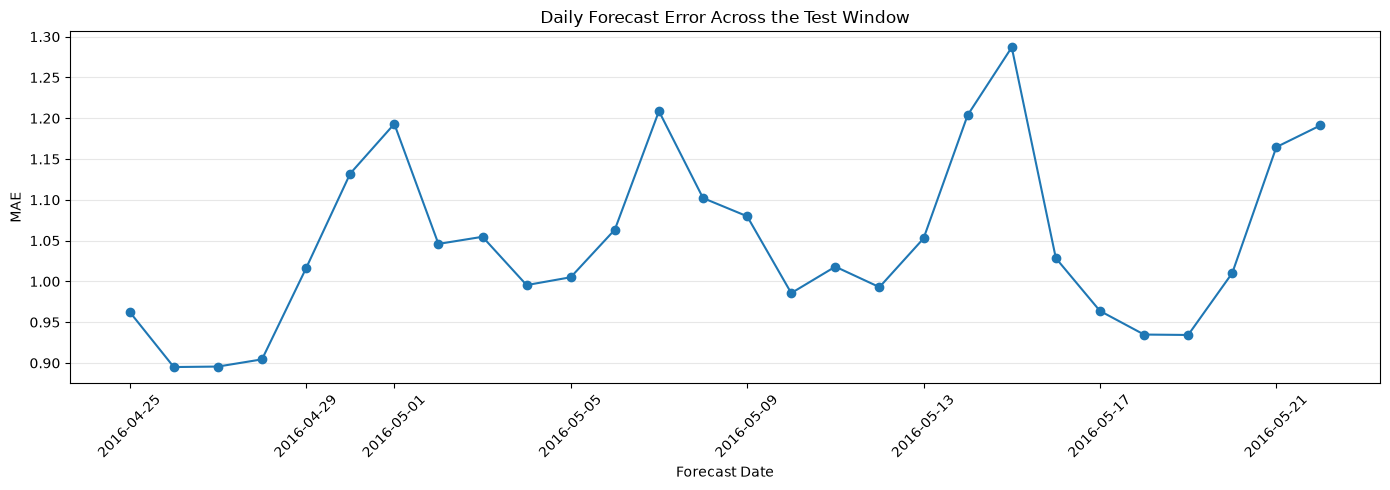

In [39]:
daily_errors = (
    pred_df.groupby("date")
    .agg(bias=("error", "mean"), mae=("abs_error", "mean"))
    .reset_index()
)


plt.figure(figsize=(14, 5))
plt.plot(daily_errors["date"], daily_errors["mae"], marker="o")

plt.xlabel("Forecast Date")
plt.ylabel("MAE")
plt.title("Daily Forecast Error Across the Test Window")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
horizon_weekday = (
    pred_df.groupby(
        [pred_df["date"].dt.day_name(),
         #"horizon_day"
         ]
    )[["error","abs_error"]]
    .mean()
    #.unstack(level=0)
)

horizon_weekday

# abs_error = |pred-actual|

,error,abs_error
date,,
Friday,-0.096653,1.035637
Monday,-0.096616,1.029216
Saturday,-0.105757,1.177344
Sunday,-0.125104,1.193368
Thursday,-0.074587,0.959199
Tuesday,-0.095730,0.974786
Wednesday,-0.097447,0.960993


In [41]:
pred_df["day_name"]=pred_df["date"].dt.day_name()
daily_errors = (
    pred_df.groupby(["cat_id","date","day_name"])
    .agg(bias=("error", "mean"), mae=("abs_error", "mean"))
    .reset_index()
)
daily_errors[daily_errors["cat_id"]=="FOODS"]

,cat_id,date,day_name,bias,mae
0,FOODS,2016-04-25,Monday,-0.114860,1.232089
1,FOODS,2016-04-26,Tuesday,-0.105138,1.130534
2,FOODS,2016-04-27,Wednesday,-0.102045,1.138133
3,FOODS,2016-04-28,Thursday,-0.084632,1.150496
4,FOODS,2016-04-29,Friday,-0.186907,1.267101
5,FOODS,2016-04-30,Saturday,-0.114334,1.410413
6,FOODS,2016-05-01,Sunday,-0.072188,1.540302
7,FOODS,2016-05-02,Monday,-0.074295,1.356921
8,FOODS,2016-05-03,Tuesday,-0.122684,1.377216
9,FOODS,2016-05-04,Wednesday,-0.146913,1.316145


In [42]:
weekday_summary = (
    pred_df.groupby(pred_df["date"].dt.day_name())
    .agg(
        mean_bias=("error", "mean"),
        mean_mae=("abs_error", "mean"),
        mean_actual_sales=("sales", "mean"),
        mean_predicted_sales=("prediction", "mean"),
    )
    .reset_index()
).sort_values("mean_mae", ascending=False)


weekday_summary

,date,mean_bias,mean_mae,mean_actual_sales,mean_predicted_sales
3,Sunday,-0.125104,1.193368,1.745654,1.620551
2,Saturday,-0.105757,1.177344,1.725927,1.620169
0,Friday,-0.096653,1.035637,1.421171,1.324518
1,Monday,-0.096616,1.029216,1.399934,1.303319
5,Tuesday,-0.095730,0.974786,1.295154,1.199424
6,Wednesday,-0.097447,0.960993,1.257707,1.160260
4,Thursday,-0.074587,0.959199,1.254190,1.179603


In [43]:
horizon_by_demand = pred_df.groupby(["horizon_day", "demand_status"]).agg(
    n=("sales", "count"), bias=("error", "mean"), mae=("abs_error", "mean")
).reset_index()
horizon_by_demand

,horizon_day,demand_status,n,bias,mae
0,1 days,positive_sales,12955,-0.925620,1.498192
1,1 days,zero_sales,17535,0.566812,0.566812
2,2 days,positive_sales,12555,-0.911542,1.422174
3,2 days,zero_sales,17935,0.525972,0.525972
4,3 days,positive_sales,12361,-0.908554,1.437986
5,3 days,zero_sales,18129,0.525765,0.525765
6,4 days,positive_sales,12358,-0.899165,1.455016
7,4 days,zero_sales,18132,0.529165,0.529165
8,5 days,positive_sales,13768,-1.003185,1.569217
9,5 days,zero_sales,16722,0.560895,0.560895


In [44]:
intermittency_df = pred_df.merge(
    analysis_df[["item_id", "store_id", "sale_frequency"]],
    on=["item_id", "store_id"],
    how="left",
)

horizon_by_sale_frequency = intermittency_df.groupby(["sale_frequency"]).agg(
    n=("item_id", "count"), bias=("error", "mean"), mae=("abs_error", "mean")
).reset_index().sort_values("mae", ascending=False)

horizon_by_sale_frequency

,sale_frequency,n,bias,mae
2,Low intermittency,321664,-0.145342,1.751058
1,Moderately intermittent,425936,-0.053688,0.666467
0,Highly intermittent,105672,-0.137493,0.441055


In [45]:
intermittency_df = pred_df.merge(
    analysis_df[["item_id", "store_id", "sale_frequency"]],
    on=["item_id", "store_id"],
    how="left",
)


horizon_by_sale_frequency = intermittency_df.groupby(["sale_frequency","demand_status"]).agg(
    n=("item_id", "count"), bias=("error", "mean"), mae=("abs_error", "mean")
).reset_index().sort_values(["sale_frequency","mae"], ascending=False)

horizon_by_sale_frequency

,sale_frequency,demand_status,n,bias,mae
4,Low intermittency,positive_sales,231767,-0.798545,1.833424
5,Low intermittency,zero_sales,89897,1.538708,1.538708
2,Moderately intermittent,positive_sales,139641,-1.063761,1.132872
3,Moderately intermittent,zero_sales,286295,0.438976,0.438976
0,Highly intermittent,positive_sales,17432,-1.727492,1.779641
1,Highly intermittent,zero_sales,88240,0.176615,0.176615


\### Observations

- The model consistently underforecasts demand throughout the 28-day forecast horizon, as indicated by the negative bias.
- The mean absolute error follows a near-cyclical pattern across the week, increasing from Friday to Saturday and peaking on Sunday.
- This suggests that the model may be struggling to capture higher weekend demand, with Sunday showing the strongest underforecasting, as reflected by its more negative bias.
- A similar pattern is observed at the category level, suggesting that this behaviour is not limited to individual product categories.
- But there is no steep ramp of error towards the end of horizon days.
- The model consistently underforecasts the sales demand while overforecasts the zero sales but with lesser magnitude.
- Low intermittent items have stroner negative bias and prediction error still signifying that the model underforecasts sales demand
- For highly intermittent series the prediction error is lowest but still the negtaive bias as -0.137. This suggests that the model may be missing some demand events while predicting zero or near-zero sales reasonably well during many other periods.

## Error by calendar: event days, SNAP days, day-of-week, around price changes. If event-day error is 2× normal, your event features aren’t carrying their weight.

In [46]:
pred_df["is_weekend"] = pred_df["date"].dt.day_of_week >= 5

weekday_errors = (
    pred_df.groupby("day_name")
    .agg(
        n=("sales", "count"),
        mean_predicted_sales=("prediction", "mean"),
        mean_actual_sales=("sales", "mean"),
        bias=("error", "mean"),
        mae=("abs_error","mean")
    )
    .reset_index()
)
weekday_errors

,day_name,n,mean_predicted_sales,mean_actual_sales,bias,mae
0,Friday,121960,1.324518,1.421171,-0.096653,1.035637
1,Monday,121960,1.303319,1.399934,-0.096616,1.029216
2,Saturday,121960,1.620169,1.725927,-0.105757,1.177344
3,Sunday,121960,1.620551,1.745654,-0.125104,1.193368
4,Thursday,121960,1.179603,1.254190,-0.074587,0.959199
5,Tuesday,121960,1.199424,1.295154,-0.095730,0.974786
6,Wednesday,121960,1.160260,1.257707,-0.097447,0.960993


In [47]:
event_cols = ["item_id","store_id","date","event_name_1","event_type_1","snap"]
temp_df = df[event_cols]
pred_df = pred_df.merge(temp_df, on=["item_id","store_id","date"], how="left")
pred_df.head(5)

,item_id,store_id,cat_id,dept_id,state_id,date,sales,prediction,error,abs_error,squared_error,actual_zero,underforecast,overforecast,demand_status,horizon_day,day_name,is_weekend,event_name_1,event_type_1,snap
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,0.839267,-0.160733,0.160733,0.025835,False,True,False,positive_sales,1 days,Monday,False,No Event,No Event,0
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,2016-04-25,0,0.163945,0.163945,0.163945,0.026878,True,False,True,zero_sales,1 days,Monday,False,No Event,No Event,0
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,1.082707,0.082707,0.082707,0.006840,False,False,True,positive_sales,1 days,Monday,False,No Event,No Event,0
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2016-04-25,3,0.764992,-2.235008,2.235008,4.995261,False,True,False,positive_sales,1 days,Monday,False,No Event,No Event,0
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,2016-04-25,11,13.931995,2.931995,2.931995,8.596593,False,False,True,positive_sales,1 days,Monday,False,No Event,No Event,0


In [48]:
pred_df["is_event"] = np.where(pred_df["event_name_1"].eq("No Event"), 0, 1)

event_errors = (
    pred_df.groupby("is_event")
    .agg(
        n=("sales", "size"),
        bias=("error", "mean"),
        mae=("abs_error", "mean"),
        mean_predicted_sales=("prediction", "mean"),
        mean_actual_sales=("sales", "mean"),
    )
    .reset_index()
    .sort_values("mae", ascending=False)
).round(3)

event_errors

,is_event,n,bias,mae,mean_predicted_sales,mean_actual_sales
1,1,121960,-0.044,1.108,1.512,1.557
0,0,731760,-0.108,1.037,1.316,1.424


In [49]:
event_ratio = (event_errors.loc[1,"mae"]/event_errors.loc[0,"mae"]).round(3)
event_ratio


np.float64(1.068)

In [50]:
event_errors = (
    pred_df.groupby(["is_event","cat_id"])
    .agg(
        n=("sales", "size"),
        bias=("error", "mean"),
        mae=("abs_error", "mean"),
        mean_predicted_sales=("prediction", "mean"),
        mean_actual_sales=("sales", "mean"),
    )
    .reset_index()
    
)

event_errors

,is_event,cat_id,n,bias,mae,mean_predicted_sales,mean_actual_sales
0,0,FOODS,344880,-0.181838,1.348607,1.860519,2.042357
1,0,HOUSEHOLD,251280,-0.039526,0.773533,0.914163,0.953689
2,0,HOBBIES,135600,-0.046720,0.733064,0.675404,0.722124
3,1,FOODS,57480,-0.095587,1.435985,2.133362,2.228949
4,1,HOUSEHOLD,41880,0.022615,0.839625,1.067911,1.045296
5,1,HOBBIES,22600,-0.037894,0.771888,0.755734,0.793628


In [51]:
event_pivot_df = event_errors.pivot_table(
    index="cat_id", columns="is_event", values="mae"
)
event_pivot_df.rename(columns={0: "Normal-day MAE", 1: "Event-day MAE"}, inplace=True)

event_pivot_df["Change %"] = (
    event_pivot_df["Event-day MAE"] / event_pivot_df["Normal-day MAE"] - 1
) * 100
event_pivot_df

is_event,Normal-day MAE,Event-day MAE,Change %
cat_id,,,
FOODS,1.348607,1.435985,6.479166
HOUSEHOLD,0.773533,0.839625,8.544116
HOBBIES,0.733064,0.771888,5.296124


In [52]:
snap_erors = pred_df.groupby("snap").agg(
    n=("sales", "count"),
    bias=("error", "mean"),
    mae=("abs_error", "mean"),
    mean_predicted_sales=("prediction","mean"),
    mean_actual_sales=("sales","mean"),
).reset_index().round(3)

snap_erors

,snap,n,bias,mae,mean_predicted_sales,mean_actual_sales
0,0,548820,-0.101,1.020,1.290,1.391
1,1,304900,-0.095,1.095,1.441,1.536


In [53]:
snap_erors = pred_df.groupby(["snap","demand_status"]).agg(
    n=("sales", "count"),
    bias=("error", "mean"),
    mae=("abs_error", "mean"),
    mean_predicted_sales=("prediction","mean"),
    mean_actual_sales=("sales","mean"),
).reset_index().round(3)

snap_erors

,snap,demand_status,n,bias,mae,mean_predicted_sales,mean_actual_sales
0,0,positive_sales,246994,-0.939,1.553,2.152,3.091
1,0,zero_sales,301826,0.585,0.585,0.585,0.000
2,1,positive_sales,142001,-0.930,1.626,2.368,3.298
3,1,zero_sales,162899,0.633,0.633,0.633,0.000


In [54]:
snap_erors = pred_df.groupby(["snap","cat_id"]).agg(
    n=("sales", "count"),
    bias=("error", "mean"),
    mae=("abs_error", "mean"),
    mean_predicted_sales=("prediction","mean"),
    mean_actual_sales=("sales","mean"),
).reset_index().round(3)

snap_erors

,snap,cat_id,n,bias,mae,mean_predicted_sales,mean_actual_sales
0,0,FOODS,258660,-0.165,1.309,1.800,1.965
1,0,HOUSEHOLD,188460,-0.039,0.776,0.920,0.960
2,0,HOBBIES,101700,-0.050,0.739,0.679,0.729
3,1,FOODS,143700,-0.177,1.455,2.079,2.256
4,1,HOUSEHOLD,104700,-0.015,0.795,0.964,0.979
5,1,HOBBIES,56500,-0.037,0.738,0.701,0.738


In [55]:
snap_pivot_df = snap_erors.pivot_table(index="cat_id", columns="snap", values="mae")
snap_pivot_df.rename(columns={0: "Normal-day MAE", 1: "Snap-day MAE"}, inplace=True)

snap_pivot_df["Change %"] = (
    snap_pivot_df["Snap-day MAE"] / snap_pivot_df["Normal-day MAE"] - 1
) * 100
snap_pivot_df

snap,Normal-day MAE,Snap-day MAE,Change %
cat_id,,,
FOODS,1.309,1.455,11.153552
HOUSEHOLD,0.776,0.795,2.448454
HOBBIES,0.739,0.738,-0.135318


In [56]:
pred_df = pred_df.merge(df[["item_id","store_id","date","sell_price"]], on=["item_id","store_id","date"], how="left")
pred_df.head(5)

,item_id,store_id,cat_id,dept_id,state_id,date,sales,prediction,error,abs_error,squared_error,actual_zero,underforecast,overforecast,demand_status,horizon_day,day_name,is_weekend,event_name_1,event_type_1,snap,is_event,sell_price
0,FOODS_3_112,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,0.839267,-0.160733,0.160733,0.025835,False,True,False,positive_sales,1 days,Monday,False,No Event,No Event,0,0,2.98
1,FOODS_3_380,TX_2,FOODS,FOODS_3,TX,2016-04-25,0,0.163945,0.163945,0.163945,0.026878,True,False,True,zero_sales,1 days,Monday,False,No Event,No Event,0,0,1.98
2,FOODS_3_719,TX_2,FOODS,FOODS_3,TX,2016-04-25,1,1.082707,0.082707,0.082707,0.006840,False,False,True,positive_sales,1 days,Monday,False,No Event,No Event,0,0,2.50
3,FOODS_3_104,TX_2,FOODS,FOODS_3,TX,2016-04-25,3,0.764992,-2.235008,2.235008,4.995261,False,True,False,positive_sales,1 days,Monday,False,No Event,No Event,0,0,2.98
4,FOODS_3_080,TX_2,FOODS,FOODS_3,TX,2016-04-25,11,13.931995,2.931995,2.931995,8.596593,False,False,True,positive_sales,1 days,Monday,False,No Event,No Event,0,0,1.68


In [57]:
pred_df["previous_price"] = pred_df.groupby(["item_id", "store_id"])[
    "sell_price"
].shift(1)

pred_df["price_changed"] = (
    pred_df["sell_price"].notna()
    & pred_df["previous_price"].notna()
    & ~np.isclose(pred_df["sell_price"], pred_df["previous_price"])
)

price_errors = pred_df.groupby("price_changed").agg(
    n=("sales", "count"), bias=("error", "mean"), mae=("abs_error", "mean")
)

price_errors

,n,bias,mae
price_changed,,,
False,852866,-0.098722,1.047024
True,854,-0.218419,1.243138


In [58]:
price_errors = pred_df.groupby(["price_changed","cat_id"]).agg(
    n=("sales", "count"), bias=("error", "mean"), mae=("abs_error", "mean")
)

price_errors

n      bias       mae
price_changed cat_id                               
False         FOODS      401941 -0.169353  1.360675
              HOUSEHOLD  292928 -0.030563  0.782974
              HOBBIES    157997 -0.045407  0.738654
True          FOODS         419 -0.326324  1.758396
              HOUSEHOLD     232 -0.139316  0.783495
              HOBBIES       203 -0.086101  0.704933

### Observations

- Mean absolute error is higher on non-event, non-SNAP, and no-price-change days than on the corresponding event, SNAP, and price-change days.
- The model consistently underforecasts demand across all the calendar conditions analysed, including event and non-event days, SNAP and non-SNAP days, and dates with and without price changes.
- The underforecasting bias is closer to zero on event and SNAP days than on their respective comparison days, although this does not necessarily mean that overall prediction accuracy is better.
- Price-change dates have higher mean absolute error and stronger underforecasting bias. However, this group contains only 854 observations, so the result should be interpreted cautiously.
- FOODS appears to be a major contributor to forecast errors, based on the category-level analysis.
- These results suggest that the model may be struggling to capture some demand variations associated with calendar events, SNAP days, and price changes. The consistent underforecasting, particularly when demand increases, warrants further investigation to determine whether the model is missing demand spikes or other demand patterns.

## 
- Pull the 10 worst and 10 best series (by weighted error) and plot actual vs predicted. Eyeballing beats statistics here: you’ll see missed spikes (model too smooth), lagging (reacts a week late), or phantom demand (predicts sales during dead periods). Each pattern points at a different fix.
- Cross-reference with features: are the worst series short-history items? Recently price-changed? One store? That links the error back to a cause you can name.

In [59]:
weighted_df = weighted_slice_errors(merge_df, ["item_id","store_id"])
weighted_df = weighted_df[weighted_df["total_weight"]>0]

worst_10 = weighted_df.nlargest(10, "weighted_error_contribution")
best_10 = weighted_df.nsmallest(10,"weighted_error_contribution")

best_10

,item_id,store_id,n_series,mean_rmsse,median_rmsse,weighted_error_contribution,total_weight,share_of_weighted_error
14361,FOODS_3_827,TX_2,1,0.00,0.00,0.000000e+00,3.201554e-06,0.000000e+00
19239,HOBBIES_2_073,CA_4,1,0.03,0.03,4.001942e-09,1.333981e-07,5.192365e-09
19760,HOBBIES_2_125,TX_1,1,0.02,0.02,5.175846e-09,2.587923e-07,6.715460e-09
19369,HOBBIES_2_086,CA_4,1,0.03,0.03,7.763769e-09,2.587923e-07,1.007319e-08
12559,FOODS_3_644,CA_3,1,0.01,0.01,8.003885e-09,8.003885e-07,1.038473e-08
19803,HOBBIES_2_129,WI_1,1,0.07,0.07,8.590836e-09,1.227262e-07,1.114628e-08
18759,HOBBIES_2_025,CA_4,1,0.04,0.04,1.067185e-08,2.667961e-07,1.384631e-08
19112,HOBBIES_2_060,TX_3,1,0.05,0.05,1.293961e-08,2.587923e-07,1.678865e-08
14970,HOBBIES_1_062,TX_1,1,0.03,0.03,1.552754e-08,5.175846e-07,2.014638e-08
28452,HOUSEHOLD_2_314,WI_2,1,0.03,0.03,1.576765e-08,5.255884e-07,2.045792e-08


In [76]:
rmsse_df = slice_errors(merge_df,["item_id","store_id"])

worst_10 = weighted_df.nlargest(10, "mean_rmsse")
best_10 = weighted_df.nsmallest(10,"mean_rmsse")
best_10

,item_id,store_id,n_series,mean_rmsse,median_rmsse,weighted_error_contribution,total_weight,share_of_weighted_error
14361,FOODS_3_827,TX_2,1,0.00,0.00,0.000000e+00,3.201554e-06,0.000000e+00
14168,FOODS_3_808,CA_3,1,0.01,0.01,2.968908e-07,2.968908e-05,3.852043e-07
10159,FOODS_3_404,CA_3,1,0.01,0.01,1.251807e-07,1.251807e-05,1.624172e-07
13758,FOODS_3_767,CA_3,1,0.01,0.01,4.471503e-08,4.471503e-06,5.801603e-08
24176,HOUSEHOLD_1_427,CA_3,1,0.01,0.01,3.969927e-08,3.969927e-06,5.150826e-08
12559,FOODS_3_644,CA_3,1,0.01,0.01,8.003885e-09,8.003885e-07,1.038473e-08
6808,FOODS_3_069,CA_2,1,0.02,0.02,6.519430e-07,3.259715e-05,8.458709e-07
12469,FOODS_3_635,CA_3,1,0.02,0.02,6.029593e-07,3.014796e-05,7.823164e-07
9309,FOODS_3_319,CA_3,1,0.02,0.02,3.882418e-07,1.941209e-05,5.037287e-07
27697,HOUSEHOLD_2_239,CA_4,1,0.02,0.02,2.911280e-07,1.455640e-05,3.777273e-07


In [77]:
import math

def plot_top_series(series_df, pred_df, title):
    n_cols = 2
    n_rows = math.ceil(len(series_df) / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 3.5 * n_rows),
        sharex=True
    )

    axes = axes.flatten()

    for ax, (_, row) in zip(axes, series_df.iterrows()):
        item = row["item_id"]
        store = row["store_id"]

        data = pred_df[
            (pred_df["item_id"] == item) &
            (pred_df["store_id"] == store)
        ].sort_values("date")

        if data.empty:
            continue

        ax.plot(
            data["date"], data["sales"],
            marker="o", markersize=3,
            label="Actual"
        )

        ax.plot(
            data["date"], data["prediction"],
            marker="o", markersize=3,
            linestyle="--",
            label="Predicted"
        )

        ax.set_title(
            f"{item} | {store}\n"
            #f"Weighted error: {row['weighted_error_contribution']:.5f}"
        )
        ax.set_ylabel("Sales")
        ax.grid(axis="y", alpha=0.3)
        ax.legend(fontsize=8)

    for ax in axes[len(series_df):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    plt.show()

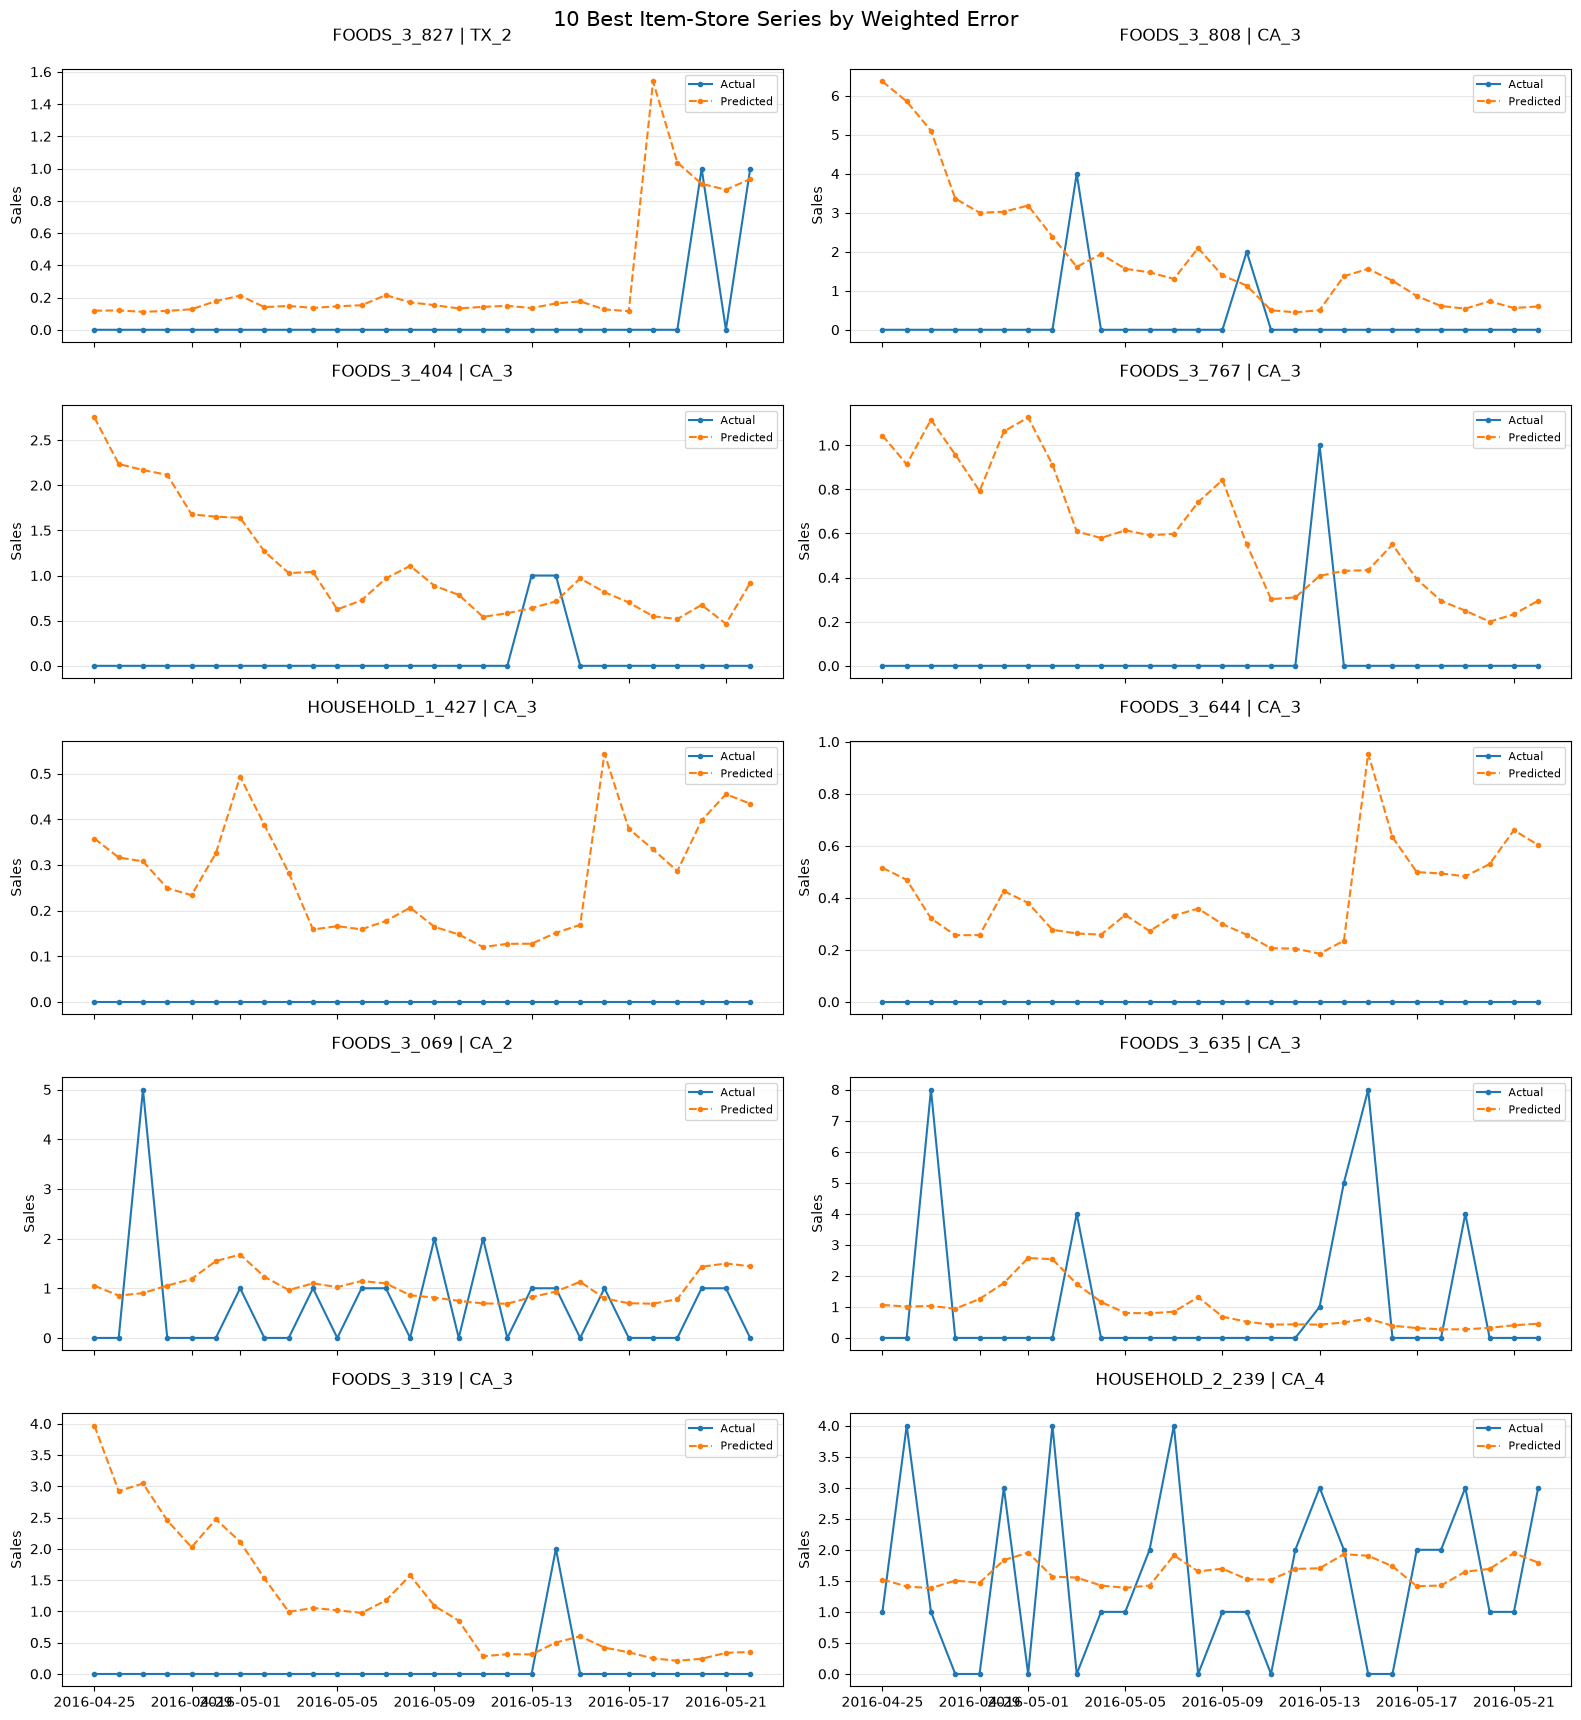

In [79]:
plot_top_series(
    best_10,
    pred_df,
    "10 Best Item-Store Series by Weighted Error"
)

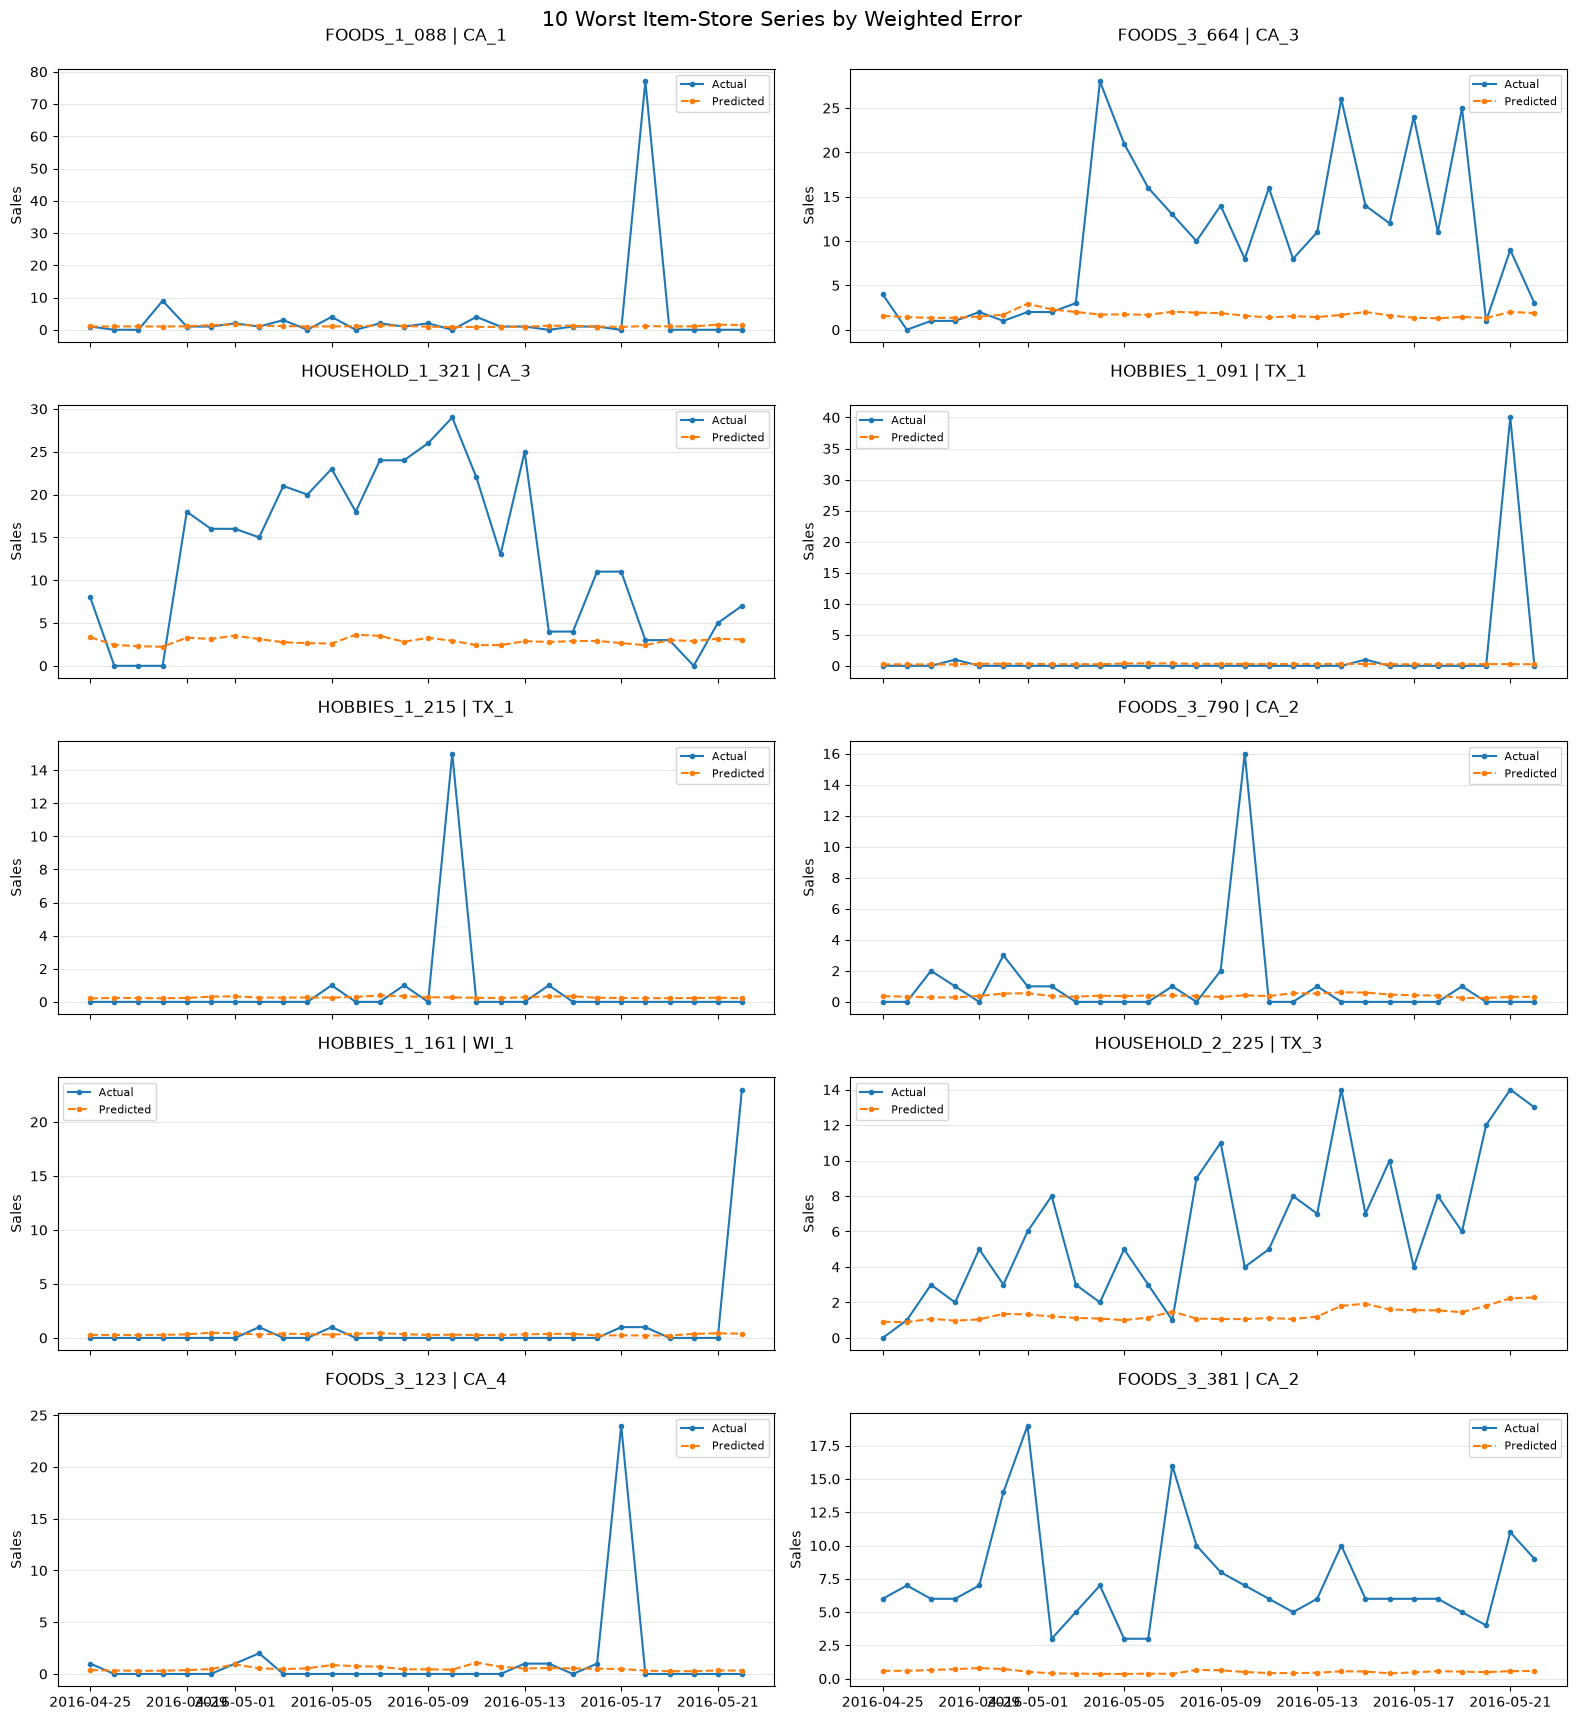

In [80]:
plot_top_series(
    worst_10,
    pred_df,
    "10 Worst Item-Store Series by Weighted Error"
)

In [93]:
temp_df = train_df[(train_df["item_id"]=="FOODS_1_088")&(train_df["store_id"]=="CA_1") & (train_df["year"]>=2015)].tail(50)
temp_df[temp_df["sales"]>=5]

,item_id,store_id,state_id,cat_id,dept_id,d,date,wm_yr_wk,launch_date,year,month,weekday,sell_price,event_name_1,event_type_1,snap,sales,week_of_year,day_of_week,day_of_month,is_weekend,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_35,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_42,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_49,lag_28,lag_29,lag_30,lag_31,lag_32,lag_33,lag_34,lag_56,rolling_positive_rate_7,rolling_positive_rate_28,rolling_zero_rate_28,days_since_last_sale,rolling_mean_7,rolling_mean_28,rolling_mean_56,rolling_positive_mean_7,rolling_positive_mean_28,rolling_positive_median_28,rolling_positive_std_28,rolling_positive_max_28,price_unique_count,price_max,price_min,price_mean,price_norm,price_weekly_change,price_change_m,price_change_y,price_vs_usual,price_vs_dept,store_dept_rolling_avg,enc_item_mean,enc_item_std,enc_store_mean,enc_store_std,enc_item_store_mean,enc_item_store_std,enc_store_dept_mean,enc_store_dept_std,enc_store_cat_mean,enc_store_cat_std,trend_28_vs_long,trend_7_vs_28,trend_28_vs_56,item_vs_dept,item_vs_cat,item_store_vs_global
13460043,FOODS_1_088,CA_1,CA,FOODS,FOODS_1,1878,2016-03-20,11608,2013-01-01,2016,3,Sunday,5.28,No Event,No Event,0,5,11,7,20,1,4,3,1,3,0,0,4,3,1,0,2,1,1,4,2,0,1,2,2,2,1,0,1,4,0,0,2,1,0,0,1,0,0.43,0.64,0.36,30,0.57,0.57,0.57,1.33,2.28,2.0,1.41,6,2,5.28,4.74,5.02,1.0,1.0,1.0,1.0,1.05,1.59,318.93,1.297908,2.295789,1.540449,4.158547,1.153444,1.824545,1.589815,3.170801,2.247861,5.497169,0.580869,1.0,1.0,0.421433,0.298061,0.888695
14404467,FOODS_1_088,CA_1,CA,FOODS,FOODS_1,1909,2016-04-20,11612,2013-01-01,2016,4,Wednesday,5.28,No Event,No Event,0,7,16,3,20,0,1,0,0,1,0,1,1,4,0,0,0,0,1,0,1,0,2,2,0,1,0,0,0,1,0,2,1,5,4,0,1,1,0.71,0.82,0.18,29,1.86,1.86,1.86,2.60,2.39,2.0,1.27,5,2,5.28,4.74,5.02,1.0,1.0,1.0,1.0,1.05,1.59,319.57,1.297963,2.284245,1.537382,4.137262,1.171477,1.818755,1.585702,3.161903,2.240706,5.463940,1.673101,1.0,1.0,1.236045,0.874724,0.902551
14495363,FOODS_1_088,CA_1,CA,FOODS,FOODS_1,1912,2016-04-23,11613,2013-01-01,2016,4,Saturday,5.28,No Event,No Event,0,5,16,6,23,1,2,0,3,1,0,0,1,4,0,1,1,0,0,0,0,3,1,0,1,2,2,0,1,0,0,0,0,0,2,1,5,2,0.43,0.71,0.29,32,1.14,1.14,1.14,2.67,2.45,2.0,1.36,5,2,5.28,4.74,5.02,1.0,1.0,1.0,1.0,1.05,1.59,335.54,1.301270,2.288900,1.537669,4.136748,1.168501,1.817399,1.587349,3.166791,2.241152,5.463085,1.061188,1.0,1.0,0.781177,0.553287,0.897970


In [95]:
temp_df = test_df[(test_df["item_id"]=="FOODS_1_088")&(test_df["store_id"]=="CA_1")].tail(50)
temp_df[temp_df["sales"]>=5]

,item_id,store_id,cat_id,dept_id,state_id,date,sales,sell_price,pred_global,pred_store,prediction,series_id
247123,FOODS_1_088,CA_1,FOODS,FOODS_1,CA,2016-04-28,9,5.28,1.008721,1.123244,1.008721,FOODS_1_088_CA_1
275873,FOODS_1_088,CA_1,FOODS,FOODS_1,CA,2016-05-18,77,5.28,1.143916,1.130619,1.143916,FOODS_1_088_CA_1


In [97]:
temp_df = train_df[(train_df["item_id"]=="FOODS_3_381")&(train_df["store_id"]=="CA_2") & (train_df["year"]>=2015)].tail(50)
temp_df

,item_id,store_id,state_id,cat_id,dept_id,d,date,wm_yr_wk,launch_date,year,month,weekday,sell_price,event_name_1,event_type_1,snap,sales,week_of_year,day_of_week,day_of_month,is_weekend,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_35,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_42,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_49,lag_28,lag_29,lag_30,lag_31,lag_32,lag_33,lag_34,lag_56,rolling_positive_rate_7,rolling_positive_rate_28,rolling_zero_rate_28,days_since_last_sale,rolling_mean_7,rolling_mean_28,rolling_mean_56,rolling_positive_mean_7,rolling_positive_mean_28,rolling_positive_median_28,rolling_positive_std_28,rolling_positive_max_28,price_unique_count,price_max,price_min,price_mean,price_norm,price_weekly_change,price_change_m,price_change_y,price_vs_usual,price_vs_dept,store_dept_rolling_avg,enc_item_mean,enc_item_std,enc_store_mean,enc_store_std,enc_item_store_mean,enc_item_store_std,enc_store_dept_mean,enc_store_dept_std,enc_store_cat_mean,enc_store_cat_std,trend_28_vs_long,trend_7_vs_28,trend_28_vs_56,item_vs_dept,item_vs_cat,item_store_vs_global
13019011,FOODS_3_381,CA_2,CA,FOODS,FOODS_3,1864,2016-03-06,11606,2013-01-01,2016,3,Sunday,2.98,No Event,No Event,1,0,9,7,6,1,0,0,0,0,0,2,3,7,5,10,3,5,3,4,7,8,6,6,3,1,5,5,7,8,11,9,7,5,3,2,3,0,1.00,0.96,0.04,28,5.71,5.71,5.71,5.71,4.67,4.0,2.63,11,3,2.98,2.48,2.93,1.00,1.00,1.12,1.05,1.02,1.02,1728.29,1.309530,1.993469,1.199431,2.934843,0.571933,1.331657,1.811584,4.191966,1.702651,3.809346,10.158534,1.0,1.0,3.207138,3.412326,0.436747
13049511,FOODS_3_381,CA_2,CA,FOODS,FOODS_3,1865,2016-03-07,11606,2013-01-01,2016,3,Monday,2.98,No Event,No Event,1,0,10,1,7,0,0,0,0,0,0,0,2,3,3,5,10,3,5,3,4,3,7,6,6,3,1,5,5,5,7,11,9,7,5,3,2,5,1.00,0.96,0.04,28,6.29,6.29,6.29,6.29,4.74,4.0,2.67,11,3,2.98,2.48,2.93,1.00,1.00,1.12,1.05,1.02,1.02,1729.75,1.311467,1.995612,1.199391,2.934439,0.577601,1.344687,1.811602,4.191620,1.702557,3.808784,11.062992,1.0,1.0,3.527264,3.753178,0.440424
13079919,FOODS_3_381,CA_2,CA,FOODS,FOODS_3,1866,2016-03-08,11606,2013-01-01,2016,3,Tuesday,2.98,No Event,No Event,1,0,10,2,8,0,0,0,0,0,0,0,0,2,2,3,5,10,3,5,3,2,4,7,6,6,3,1,5,0,5,7,11,9,7,5,3,2,1.00,0.96,0.04,28,6.71,6.71,6.71,6.71,4.85,4.0,2.61,11,3,2.98,2.48,2.93,1.00,1.00,1.12,1.05,1.02,1.02,1735.93,1.312075,1.995544,1.199355,2.934179,0.581498,1.350489,1.811726,4.191523,1.702525,3.808453,11.711136,1.0,1.0,3.758846,3.999942,0.443189
13110503,FOODS_3_381,CA_2,CA,FOODS,FOODS_3,1867,2016-03-09,11606,2013-01-01,2016,3,Wednesday,2.98,No Event,No Event,1,0,10,3,9,0,0,0,0,0,0,0,0,3,0,2,3,5,10,3,5,3,3,4,7,6,6,3,1,3,5,5,7,11,9,7,5,2,1.00,0.96,0.04,28,7.00,7.00,7.00,7.00,4.96,5.0,2.55,11,3,2.98,2.48,2.93,1.00,1.00,1.12,1.05,1.02,1.02,1752.93,1.313212,1.996144,1.199331,2.934084,0.585387,1.356244,1.811906,4.191663,1.702503,3.808188,12.128722,1.0,1.0,3.918525,4.170330,0.445768
13140895,FOODS_3_381,CA_2,CA,FOODS,FOODS_3,1868,2016-03-10,11606,2013-01-01,2016,3,Thursday,2.98,No Event,No Event,1,0,10,4,10,0,0,0,0,0,0,0,0,5,0,0,2,3,5,10,3,6,5,3,4,7,6,6,3,4,1,5,5,7,11,9,7,5,1.00,0.96,0.04,28,6.43,6.43,6.43,6.43,4.81,4.0,2.66,11,3,2.98,2.48,2.93,1.00,1.00,1.12,1.05,1.02,1.02,1770.21,1.313729,1.996420,1.199458,2.933973,0.585752,1.355703,1.812370,4.191921,1.702741,3.808092,11.148063,1.0,1.0,3.603017,3.834993,0.445870
13172035,FOODS_3_381,CA_2,CA,FOODS,FOODS_3,1869,2016-03-11,11606,2013-01-01,2016,3,Friday,2.98,No Event,No Event,0,0,10,5,11,0,0,0,0,0,0,0,0,7,0,0,0,2,3,5,10,4,3,5,3,4,7,6,6,1,3,1,5,5,7,11,9,2,1.00,0.96,0.04,28,5.86,5.86,5.86,5.86,4.85,4.0,2.63,11,3,2.98,2.48,2.93,1.00,1.00,1.12,1.05,1.02,1.02,1772.93,1.314862,1.997150,1.199624,2.934063,0.587873,1.356995,1.812690,4.192124,1.702987,3.808149,10.138236,1.0,1.0,3.287932,3.499732,0.447099
13202494,FOODS_3_381,CA_2,CA,FOODS,FOODS_3,1870,2016-03-12,11607,2013-01-01,2016,3,Saturday,2.48,No Event,No Event,0,1,10,6,12,1,0,0,0,0,0,0,0,9,0,0,0,0,2,3,5,3,10,3,5,3,4,7,6,9,6,3,1,5,5,7,11,4,1.00,0.96,0.04,28,5.43,5.43,5.43,5.43,4.93,5.0,2.63,11,3,2.98,2.48,2.93,0.83,0.83

In [98]:
temp_df = test_df[(test_df["item_id"]=="FOODS_3_381")&(test_df["store_id"]=="CA_2")].tail(50)
temp_df

,item_id,store_id,cat_id,dept_id,state_id,date,sales,sell_price,pred_global,pred_store,prediction,series_id
363203,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-04-25,6,2.98,0.592782,0.755740,0.592782,FOODS_3_381_CA_2
364694,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-04-26,7,2.98,0.592258,0.742932,0.592258,FOODS_3_381_CA_2
366131,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-04-27,6,2.98,0.655955,0.811869,0.655955,FOODS_3_381_CA_2
367517,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-04-28,6,2.98,0.722000,0.869862,0.722000,FOODS_3_381_CA_2
368668,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-04-29,7,2.98,0.800636,0.856274,0.800636,FOODS_3_381_CA_2
370464,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-04-30,14,2.98,0.728561,0.924240,0.728561,FOODS_3_381_CA_2
371798,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-05-01,19,2.98,0.528300,0.740900,0.528300,FOODS_3_381_CA_2
373336,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-05-02,3,2.98,0.398138,0.539233,0.398138,FOODS_3_381_CA_2
374680,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-05-03,5,2.98,0.385440,0.535284,0.385440,FOODS_3_381_CA_2
375746,FOODS_3_381,CA_2,FOODS,FOODS_3,CA,2016-05-04,7,2.98,0.363245,0.532724,0.363245,FOODS_3_381_CA_2
